# Complete Engineering Traction3D

Run all cells in your OneSimulation environment. The recorded output below was generated by executing this code. The spatial view uses the solved forces, eigenvectors or stress tensor.

Principal stresses [MPa]: [-32.36403   8.38381  93.98022]
Absolute maximum shear [MPa]: 63.17212


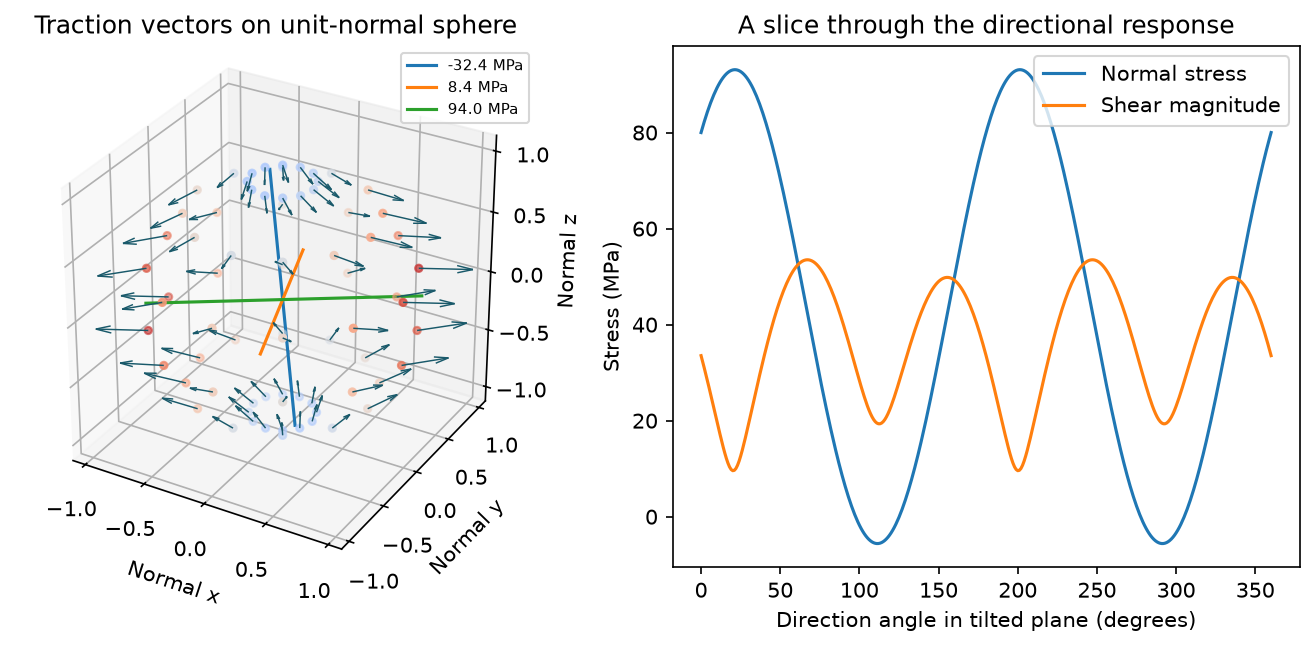

In [1]:
"""Compute principal stresses with OneSimulation and show Cauchy traction in 3D."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.linear.matrices.dense_linear_algebra import symmetric_eigensystem

# Symmetric Cauchy tensor in MPa; edit the entries to reproduce the browser controls.
sigma=np.array([[80.,30.,15.],[30.,20.,0.],[15.,0.,-30.]])
principal, axes = symmetric_eigensystem(sigma)
assert np.allclose(axes@np.diag(principal)@axes.T,sigma)
assert np.allclose(axes.T@axes,np.eye(3))
print('Principal stresses [MPa]:',np.round(principal,5))
print('Absolute maximum shear [MPa]:',round((principal[-1]-principal[0])/2,5))
phi=np.linspace(0,2*np.pi,12,endpoint=False)
theta=np.linspace(.25,np.pi-.25,6)
n=np.array([[np.sin(t)*np.cos(p),np.sin(t)*np.sin(p),np.cos(t)] for t in theta for p in phi])
traction=n@sigma.T
normal=np.sum(n*traction,axis=1)
shear=traction-normal[:,None]*n
assert np.max(abs(np.sum(n*shear,axis=1)))<1e-12
assert normal.min()>=principal[0]-1e-10 and normal.max()<=principal[-1]+1e-10
fig=plt.figure(figsize=(9,4.2),layout='constrained');ax=fig.add_subplot(121,projection='3d')
ax.quiver(*n.T,*(traction/120).T,length=.5,normalize=False,color='#19596a',linewidth=.7)
ax.scatter(*n.T,c=normal,cmap='coolwarm',s=12,vmin=-100,vmax=100)
for j in range(3):ax.plot(*np.array([-axes[:,j],axes[:,j]]).T,label=f'{principal[j]:.1f} MPa')
ax.set(xlabel='Normal x',ylabel='Normal y',zlabel='Normal z',title='Traction vectors on unit-normal sphere')
ax.set_box_aspect((1,1,1));ax.legend(fontsize=7)
a=np.linspace(0,2*np.pi,361);incline=np.deg2rad(30)
directions=np.column_stack((np.cos(a),np.sin(a)*np.cos(incline),np.sin(a)*np.sin(incline)))
t=directions@sigma.T;sn=np.sum(t*directions,axis=1);st=np.linalg.norm(t-sn[:,None]*directions,axis=1)
ax2=fig.add_subplot(122);ax2.plot(np.rad2deg(a),sn,label='Normal stress');ax2.plot(np.rad2deg(a),st,label='Shear magnitude')
ax2.set(xlabel='Direction angle in tilted plane (degrees)',ylabel='Stress (MPa)',title='A slice through the directional response');ax2.legend()
fig.savefig('complete-engineering-traction3d.png',dpi=170);plt.show()
